In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [3]:
import pandas as pd
import numpy as np 


In [4]:
df1 = pd.read_csv('/kaggle/input/datasets/samnikolas/eeg-dataset/features_raw.csv')
df2 = pd.read_csv('/kaggle/input/datasets/harunshimanto/epileptic-seizure-recognition/Epileptic Seizure Recognition.csv')
df3 = pd.read_csv('/kaggle/input/datasets/ahmeduzaki/eeg-eye-state-detection-dataset/EEG-Eye-State.csv')


In [5]:
df1.head()

,Fp1,AF3,F3,F7,FC5,FC1,C3,T7,CP5,CP1,...,Cz,C4,T8,CP6,CP2,P4,P8,PO4,O2,Unnamed: 32
0,0.057813,-1.335266,4.640480,0.219573,7.473817,2.314842,1.918097,-9.257533,9.089943,-7.104519,...,-2.241480,1.415335,2.406646,12.864059,4.021099,-2.828598,-2.588735,2.637905,-5.226618,NaN
1,1.367408,10.259654,3.345409,7.897852,-2.446051,-1.655035,-6.301423,-7.290317,-3.546453,-5.705187,...,-2.568397,-5.651418,-0.096730,-4.930759,-1.722504,-6.111309,0.094893,-3.521353,1.887093,NaN
2,-1.783132,4.133553,-0.951680,-1.624803,-1.827309,-2.280364,-2.279225,9.151344,-0.239575,-0.057604,...,-2.132823,-0.521117,8.605298,-4.499946,-3.232839,-4.249645,-3.687167,-7.383004,-4.489537,NaN
3,-3.690217,-0.814000,2.295469,0.901445,8.323679,1.127906,6.356886,11.642082,9.354154,-1.662478,...,-0.506117,-1.154866,-3.940251,7.390881,2.129897,-0.794675,-1.959021,2.774530,-6.323060,NaN
4,2.137114,6.420466,6.122230,10.015321,3.106394,3.183129,3.658535,4.571793,4.917712,-2.325940,...,1.813907,-6.444635,-27.680880,0.641364,1.996658,-0.445779,2.614021,6.161845,3.308816,NaN


In [6]:
df1 = df1.iloc[:,:-1]

In [7]:
df1.head()

,Fp1,AF3,F3,F7,FC5,FC1,C3,T7,CP5,CP1,...,FC2,Cz,C4,T8,CP6,CP2,P4,P8,PO4,O2
0,0.057813,-1.335266,4.640480,0.219573,7.473817,2.314842,1.918097,-9.257533,9.089943,-7.104519,...,-30.579542,-2.241480,1.415335,2.406646,12.864059,4.021099,-2.828598,-2.588735,2.637905,-5.226618
1,1.367408,10.259654,3.345409,7.897852,-2.446051,-1.655035,-6.301423,-7.290317,-3.546453,-5.705187,...,-1.290516,-2.568397,-5.651418,-0.096730,-4.930759,-1.722504,-6.111309,0.094893,-3.521353,1.887093
2,-1.783132,4.133553,-0.951680,-1.624803,-1.827309,-2.280364,-2.279225,9.151344,-0.239575,-0.057604,...,11.424923,-2.132823,-0.521117,8.605298,-4.499946,-3.232839,-4.249645,-3.687167,-7.383004,-4.489537
3,-3.690217,-0.814000,2.295469,0.901445,8.323679,1.127906,6.356886,11.642082,9.354154,-1.662478,...,-14.721411,-0.506117,-1.154866,-3.940251,7.390881,2.129897,-0.794675,-1.959021,2.774530,-6.323060
4,2.137114,6.420466,6.122230,10.015321,3.106394,3.183129,3.658535,4.571793,4.917712,-2.325940,...,-13.815090,1.813907,-6.444635,-27.680880,0.641364,1.996658,-0.445779,2.614021,6.161845,3.308816


In [8]:
df2.head()

,Unnamed,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X170,X171,X172,X173,X174,X175,X176,X177,X178,y
0,X21.V1.791,135,190,229,223,192,125,55,-9,-33,...,-17,-15,-31,-77,-103,-127,-116,-83,-51,4
1,X15.V1.924,386,382,356,331,320,315,307,272,244,...,164,150,146,152,157,156,154,143,129,1
2,X8.V1.1,-32,-39,-47,-37,-32,-36,-57,-73,-85,...,57,64,48,19,-12,-30,-35,-35,-36,5
3,X16.V1.60,-105,-101,-96,-92,-89,-95,-102,-100,-87,...,-82,-81,-80,-77,-85,-77,-72,-69,-65,5
4,X20.V1.54,-9,-65,-98,-102,-78,-48,-16,0,-21,...,4,2,-12,-32,-41,-65,-83,-89,-73,5


In [9]:
df2['y'] = df2['y'].apply(lambda x: 1 if x == 1 else 0)

In [10]:
df2 = df2.iloc[:,1:]

In [11]:
df2.head()

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X170,X171,X172,X173,X174,X175,X176,X177,X178,y
0,135,190,229,223,192,125,55,-9,-33,-38,...,-17,-15,-31,-77,-103,-127,-116,-83,-51,0
1,386,382,356,331,320,315,307,272,244,232,...,164,150,146,152,157,156,154,143,129,1
2,-32,-39,-47,-37,-32,-36,-57,-73,-85,-94,...,57,64,48,19,-12,-30,-35,-35,-36,0
3,-105,-101,-96,-92,-89,-95,-102,-100,-87,-79,...,-82,-81,-80,-77,-85,-77,-72,-69,-65,0
4,-9,-65,-98,-102,-78,-48,-16,0,-21,-59,...,4,2,-12,-32,-41,-65,-83,-89,-73,0


In [12]:
df3 = pd.read_csv('/kaggle/input/datasets/ahmeduzaki/eeg-eye-state-detection-dataset/EEG-Eye-State.csv')
df3.sample(5)

,AF3,AF4,F3,F4,F7,F8,FC5,FC6,T7,T8,P7,P8,O1,O2,eyeDetection
3992,4280.51,4341.03,4256.92,4262.05,4011.79,4605.64,4116.41,4186.67,4330.77,4209.74,4607.69,4181.54,4033.85,4600.51,1
1169,4310.26,4358.46,4264.62,4284.10,4016.41,4602.56,4132.31,4201.03,4337.95,4222.05,4573.33,4192.31,4086.67,4604.62,0
2525,4306.15,4368.72,4268.72,4281.03,4013.33,4593.33,4136.41,4195.90,4331.79,4222.05,4601.54,4195.90,4057.95,4598.46,1
2733,4275.90,4327.18,4250.26,4276.92,3994.36,4585.13,4108.21,4197.95,4330.77,4230.26,4614.36,4201.54,4078.46,4617.44,0
3856,4258.97,4327.69,4231.28,4242.56,4006.15,4606.15,4100.00,4188.72,4331.28,4220.51,4614.36,4193.33,4035.38,4594.36,1


In [14]:
df1.describe()

,Fp1,AF3,F3,F7,FC5,FC1,C3,T7,CP5,CP1,...,FC2,Cz,C4,T8,CP6,CP2,P4,P8,PO4,O2
count,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000,...,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000,8064.000000
mean,-0.030110,0.049626,-0.000615,0.012063,-0.072324,-0.005855,-0.051846,0.080661,-0.123370,0.048696,...,0.428362,0.022278,0.005247,0.089107,-0.143788,-0.063250,-0.009944,0.085996,-0.150934,-0.025165
std,4.303870,19.050580,4.949803,19.530056,14.974316,5.223861,14.165469,20.447003,24.640017,12.291358,...,87.646383,3.967493,11.566574,23.461405,37.118809,21.967885,13.279541,12.283903,37.205713,9.351170
min,-21.068011,-174.162043,-32.576432,-119.687503,-104.400666,-31.009221,-102.940922,-175.751521,-181.618505,-107.664139,...,-839.742441,-27.511152,-63.660644,-190.817674,-264.707312,-154.697176,-92.928548,-107.039803,-257.126150,-61.072350
25%,-2.741710,-6.946013,-2.907836,-8.685504,-5.854239,-2.613004,-4.874130,-9.294624,-7.736768,-5.723207,...,-27.358855,-2.428667,-5.443370,-12.156545,-11.501669,-7.169325,-4.741264,-4.863120,-12.069369,-4.147790
50%,0.065934,0.079142,0.016822,0.050682,-0.196773,-0.023871,-0.055134,0.028703,-0.234875,0.190146,...,1.021705,0.046393,0.014605,0.209449,-0.361638,-0.106215,0.022058,0.068265,-0.410909,-0.133808
75%,2.800696,7.236850,2.968202,8.973624,5.405050,2.623072,4.686449,9.383725,7.317881,5.932243,...,29.398781,2.435290,5.497645,12.253631,11.114534,6.803120,4.486082,5.201910,11.340294,4.129460
max,18.633981,128.729493,33.843385,120.164457,140.707711,38.313366,133.738083,129.284111,247.950230,86.087539,...,598.454543,23.901393,73.879081,154.613511,366.740914,214.349394,126.611391,86.421457,361.662396,84.408689


In [15]:
df2.describe()

,X1,X2,X3,X4,X5,X6,X7,X8,X9,X10,...,X170,X171,X172,X173,X174,X175,X176,X177,X178,y
count,11500.000000,11500.000000,11500.000000,11500.000000,11500.000000,11500.000000,11500.000000,11500.00000,11500.00000,11500.000000,...,11500.000000,11500.000000,11500.000000,11500.000000,11500.000000,11500.000000,11500.000000,11500.000000,11500.000000,11500.000000
mean,-11.581391,-10.911565,-10.187130,-9.143043,-8.009739,-7.003478,-6.502087,-6.68713,-6.55800,-6.168435,...,-10.145739,-11.630348,-12.943478,-13.668870,-13.363304,-13.045043,-12.705130,-12.426000,-12.195652,0.200000
std,165.626284,166.059609,163.524317,161.269041,160.998007,161.328725,161.467837,162.11912,162.03336,160.436352,...,164.652883,166.149790,168.554058,168.556486,167.257290,164.241019,162.895832,162.886311,164.852015,0.400017
min,-1839.000000,-1838.000000,-1835.000000,-1845.000000,-1791.000000,-1757.000000,-1832.000000,-1778.00000,-1840.00000,-1867.000000,...,-1867.000000,-1865.000000,-1642.000000,-1723.000000,-1866.000000,-1863.000000,-1781.000000,-1727.000000,-1829.000000,0.000000
25%,-54.000000,-55.000000,-54.000000,-54.000000,-54.000000,-54.000000,-54.000000,-55.00000,-55.00000,-54.000000,...,-55.000000,-56.000000,-56.000000,-56.000000,-55.000000,-56.000000,-55.000000,-55.000000,-55.000000,0.000000
50%,-8.000000,-8.000000,-7.000000,-8.000000,-8.000000,-8.000000,-8.000000,-8.00000,-7.00000,-7.000000,...,-9.000000,-10.000000,-10.000000,-10.000000,-10.000000,-9.000000,-9.000000,-9.000000,-9.000000,0.000000
75%,34.000000,35.000000,36.000000,36.000000,35.000000,36.000000,35.000000,36.00000,36.00000,35.250000,...,34.000000,34.000000,33.000000,33.000000,34.000000,34.000000,34.000000,34.000000,34.000000,0.000000
max,1726.000000,1713.000000,1697.000000,1612.000000,1518.000000,1816.000000,2047.000000,2047.00000,2047.00000,2047.000000,...,1777.000000,1472.000000,1319.000000,1436.000000,1733.000000,1958.000000,2047.000000,2047.000000,1915.000000,1.000000


In [16]:
df3.describe()

,AF3,AF4,F3,F4,F7,F8,FC5,FC6,T7,T8,P7,P8,O1,O2,eyeDetection
count,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000,14980.000000
mean,4321.917777,4416.435832,4264.022433,4279.232774,4009.767694,4615.205336,4164.946326,4202.456900,4341.741075,4231.316200,4644.022379,4218.826610,4110.400160,4616.056904,0.448798
std,2492.072174,5891.285043,44.428052,41.544312,45.941672,1208.369958,5216.404632,37.785981,34.738821,38.050903,2924.789537,2136.408523,4600.926543,29.292603,0.497388
min,1030.770000,1366.150000,1040.000000,2257.950000,2830.770000,86.666700,2453.330000,3273.330000,2089.740000,1816.410000,2768.210000,1357.950000,2086.150000,4567.180000,0.000000
25%,4280.510000,4342.050000,4250.260000,4267.690000,3990.770000,4590.770000,4108.210000,4190.260000,4331.790000,4220.510000,4611.790000,4190.770000,4057.950000,4604.620000,0.000000
50%,4294.360000,4354.870000,4262.560000,4276.920000,4005.640000,4603.080000,4120.510000,4200.510000,4338.970000,4229.230000,4617.950000,4199.490000,4070.260000,4613.330000,0.000000
75%,4311.790000,4372.820000,4270.770000,4287.180000,4023.080000,4617.440000,4132.310000,4211.280000,4347.180000,4239.490000,4626.670000,4209.230000,4083.590000,4624.100000,1.000000
max,309231.000000,715897.000000,6880.510000,7002.560000,7804.620000,152308.000000,642564.000000,6823.080000,6474.360000,6674.360000,362564.000000,265641.000000,567179.000000,7264.100000,1.000000


### Data Preprocessing

In [17]:
# Drop useless column
df1 = df1.drop(columns=["Unnamed: 32"], errors="ignore")

# Handle missing values (simple approach)
df1 = df1.fillna(df1.mean())

In [18]:
df1.isnull().sum()

Fp1    0
AF3    0
F3     0
F7     0
FC5    0
FC1    0
C3     0
T7     0
CP5    0
CP1    0
P3     0
P7     0
PO3    0
O1     0
Oz     0
Pz     0
Fp2    0
AF4    0
Fz     0
F4     0
F8     0
FC6    0
FC2    0
Cz     0
C4     0
T8     0
CP6    0
CP2    0
P4     0
P8     0
PO4    0
O2     0
dtype: int64

In [19]:
# Just in case (safe cleaning)
df2 = df2.fillna(df2.mean())

In [20]:
df2.isnull().sum()

X1      0
X2      0
X3      0
X4      0
X5      0
       ..
X175    0
X176    0
X177    0
X178    0
y       0
Length: 179, dtype: int64

In [21]:
# Features
X = df3.drop(columns=["eyeDetection"])

# Target
y = df3["eyeDetection"]

In [22]:
X = X.fillna(X.mean())

In [24]:
print("Shape of X:", X.shape)
print("Shape of y:", y.shape)

Shape of X: (14980, 14)
Shape of y: (14980,)


In [25]:
print("Class distribution:\n", y.value_counts())

Class distribution:
 eyeDetection
0    8257
1    6723
Name: count, dtype: int64


In [26]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

### Denoising

In [27]:
import pandas as pd

X_scaled_df = pd.DataFrame(X_scaled)

# Apply smoothing
X_denoised = X_scaled_df.rolling(window=3, min_periods=1).mean()

In [28]:
from sklearn.feature_selection import VarianceThreshold

selector = VarianceThreshold(threshold=0.01)
X_selected = selector.fit_transform(X_denoised)

In [29]:
print("Original shape:", X.shape)
print("After Pipeline A:", X_selected.shape)

Original shape: (14980, 14)
After Pipeline A: (14980, 14)


In [30]:
import pandas as pd
import numpy as np

# Convert X to DataFrame (if not already)
X_df = pd.DataFrame(X)

# Extract statistical features row-wise
X_features = pd.DataFrame({
    "mean": X_df.mean(axis=1),
    "std": X_df.std(axis=1),
    "max": X_df.max(axis=1),
    "min": X_df.min(axis=1),
    "range": X_df.max(axis=1) - X_df.min(axis=1)
})

In [31]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled_B = scaler.fit_transform(X_features)

In [32]:
from sklearn.decomposition import PCA

pca = PCA(n_components=0.95)  # keep 95% variance
X_pca = pca.fit_transform(X_scaled_B)

In [33]:
print("Original shape:", X.shape)
print("After Feature Extraction:", X_features.shape)
print("After PCA:", X_pca.shape)

Original shape: (14980, 14)
After Feature Extraction: (14980, 5)
After PCA: (14980, 2)


## Base Model Logistic Regression

#### Train-Test Split

In [34]:
from sklearn.model_selection import train_test_split

# For Pipeline A
X_train_A, X_test_A, y_train, y_test = train_test_split(
    X_selected, y, test_size=0.2, random_state=42, stratify=y
)

# For Pipeline B
X_train_B, X_test_B, _, _ = train_test_split(
    X_pca, y, test_size=0.2, random_state=42, stratify=y
)

In [35]:
from sklearn.linear_model import LogisticRegression

# Baseline model
model_A = LogisticRegression(max_iter=1000)
model_B = LogisticRegression(max_iter=1000)

# Train
model_A.fit(X_train_A, y_train)
model_B.fit(X_train_B, y_train)

LogisticRegression(max_iter=1000)

In [36]:
# Predictions
y_pred_A = model_A.predict(X_test_A)
y_pred_B = model_B.predict(X_test_B)

# Probabilities (needed for PR-AUC)
y_prob_A = model_A.predict_proba(X_test_A)[:, 1]
y_prob_B = model_B.predict_proba(X_test_B)[:, 1]

### Evaluation Metrics

In [37]:
from sklearn.metrics import accuracy_score, f1_score, average_precision_score

# Pipeline A
acc_A = accuracy_score(y_test, y_pred_A)
f1_A = f1_score(y_test, y_pred_A)
pr_auc_A = average_precision_score(y_test, y_prob_A)

# Pipeline B
acc_B = accuracy_score(y_test, y_pred_B)
f1_B = f1_score(y_test, y_pred_B)
pr_auc_B = average_precision_score(y_test, y_prob_B)

# Print results
print("Pipeline A Results:")
print("Accuracy:", acc_A)
print("F1 Score:", f1_A)
print("PR-AUC:", pr_auc_A)

print("\nPipeline B Results:")
print("Accuracy:", acc_B)
print("F1 Score:", f1_B)
print("PR-AUC:", pr_auc_B)

Pipeline A Results:
Accuracy: 0.5801068090787717
F1 Score: 0.4348607367475292
PR-AUC: 0.5717747444536325

Pipeline B Results:
Accuracy: 0.5530707610146862
F1 Score: 0.21002949852507374
PR-AUC: 0.4891517221023207


## Analysis
`Pipeline B performed worse than Pipeline A due to excessive feature compression. The statistical feature extraction step reduced the rich multi-channel EEG data into a small set of summary statistics, resulting in significant information loss. Additionally, applying PCA on already low-dimensional features further degraded performance. This demonstrates that aggressive preprocessing can harm model performance when important structural information is lost.`

## Conclusion
`The results show that preprocessing order significantly impacts performance. While Pipeline B aimed to improve generalization through dimensionality reduction, it instead led to under-representation of the data. Pipeline A preserved more useful information, resulting in better classification performance.`

# Step 5

In [38]:
from sklearn.linear_model import LogisticRegression

# Strong regularization → UNDERFITTING
underfit_model = LogisticRegression(C=0.001, max_iter=1000)

underfit_model.fit(X_train_A, y_train)

# Evaluate
from sklearn.metrics import accuracy_score, f1_score

y_pred_under = underfit_model.predict(X_test_A)

print("Underfitting Model:")
print("Accuracy:", accuracy_score(y_test, y_pred_under))
print("F1 Score:", f1_score(y_test, y_pred_under))

Underfitting Model:
Accuracy: 0.5674232309746329
F1 Score: 0.2376470588235294


In [39]:
# Weak regularization → OVERFITTING
overfit_model = LogisticRegression(C=1000, max_iter=1000)

overfit_model.fit(X_train_A, y_train)

y_pred_over = overfit_model.predict(X_test_A)

print("Overfitting Model:")
print("Accuracy:", accuracy_score(y_test, y_pred_over))
print("F1 Score:", f1_score(y_test, y_pred_over))

Overfitting Model:
Accuracy: 0.6425233644859814
F1 Score: 0.5535639849937474


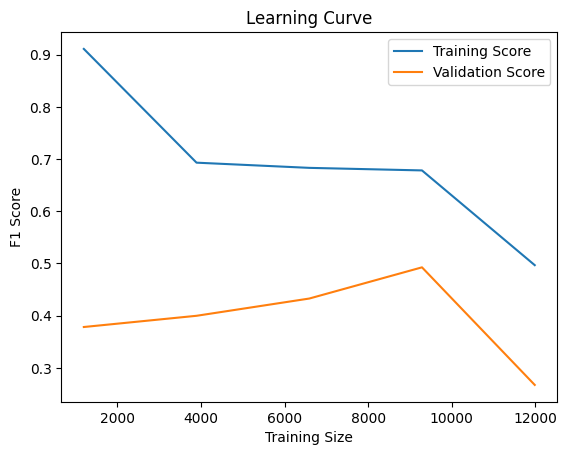

In [40]:
from sklearn.model_selection import learning_curve
import numpy as np
import matplotlib.pyplot as plt

train_sizes, train_scores, val_scores = learning_curve(
    LogisticRegression(max_iter=1000),
    X_selected,
    y,
    cv=5,
    scoring='f1',
    train_sizes=np.linspace(0.1, 1.0, 5)
)

# Mean scores
train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

# Plot
plt.plot(train_sizes, train_mean, label="Training Score")
plt.plot(train_sizes, val_mean, label="Validation Score")
plt.xlabel("Training Size")
plt.ylabel("F1 Score")
plt.legend()
plt.title("Learning Curve")
plt.show()

# Step 6 Regularization

In [42]:
from sklearn.linear_model import LogisticRegression

l1_model = LogisticRegression(
    penalty='l1',
    solver='liblinear',
    C=1.0,
    max_iter=1000
)

l1_model.fit(X_train_A, y_train)

y_pred_l1 = l1_model.predict(X_test_A)

In [41]:
l2_model = LogisticRegression(
    penalty='l2',
    solver='lbfgs',
    C=1.0,
    max_iter=1000
)

l2_model.fit(X_train_A, y_train)

y_pred_l2 = l2_model.predict(X_test_A)

In [43]:
elastic_model = LogisticRegression(
    penalty='elasticnet',
    solver='saga',
    l1_ratio=0.5,
    C=1.0,
    max_iter=1000
)

elastic_model.fit(X_train_A, y_train)

y_pred_enet = elastic_model.predict(X_test_A)

/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


In [44]:
from sklearn.metrics import f1_score, accuracy_score

print("L1 Results")
print("Accuracy:", accuracy_score(y_test, y_pred_l1))
print("F1:", f1_score(y_test, y_pred_l1))

print("\nL2 Results")
print("Accuracy:", accuracy_score(y_test, y_pred_l2))
print("F1:", f1_score(y_test, y_pred_l2))

print("\nElastic Net Results")
print("Accuracy:", accuracy_score(y_test, y_pred_enet))
print("F1:", f1_score(y_test, y_pred_enet))

L1 Results
Accuracy: 0.6244993324432577
F1: 0.5182012847965739

L2 Results
Accuracy: 0.5801068090787717
F1: 0.4348607367475292

Elastic Net Results
Accuracy: 0.5734312416555407
F1: 0.4263913824057451


L1 regularization achieved the best performance on the EEG dataset, indicating that feature selection is beneficial in high-dimensional and correlated signal data. The sparsity induced by L1 helped remove redundant or noisy EEG channels, improving classification performance.

### L2 Interpretation

L2 regularization provided stable but lower performance, as it retained all features while only shrinking their weights, which is less effective for noisy and highly correlated EEG data.

### Elastic Net Interpretation

Elastic Net did not outperform L1 or L2 individually, suggesting that combining penalties does not always improve performance when feature redundancy is highly structured.

### Step 7.1: Baseline (Class Weights)

In [45]:
from sklearn.linear_model import LogisticRegression

cw_model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000
)

cw_model.fit(X_train_A, y_train)

y_pred_cw = cw_model.predict(X_test_A)
y_prob_cw = cw_model.predict_proba(X_test_A)[:, 1]

### Step 7.2: SMOTE (Oversampling)

In [46]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(random_state=42)

X_smote, y_smote = smote.fit_resample(X_train_A, y_train)

smote_model = LogisticRegression(max_iter=1000)
smote_model.fit(X_smote, y_smote)

y_pred_smote = smote_model.predict(X_test_A)
y_prob_smote = smote_model.predict_proba(X_test_A)[:, 1]

### Step 7.3: Undersampling

In [47]:
from imblearn.under_sampling import RandomUnderSampler

rus = RandomUnderSampler(random_state=42)

X_under, y_under = rus.fit_resample(X_train_A, y_train)

under_model = LogisticRegression(max_iter=1000)
under_model.fit(X_under, y_under)

y_pred_under = under_model.predict(X_test_A)
y_prob_under = under_model.predict_proba(X_test_A)[:, 1]

### Step 7.4: Evaluation

In [48]:
from sklearn.metrics import f1_score, average_precision_score

def evaluate(name, y_true, y_pred, y_prob):
    print(f"\n{name}")
    print("F1:", f1_score(y_true, y_pred))
    print("PR-AUC:", average_precision_score(y_true, y_prob))

evaluate("Class Weight", y_test, y_pred_cw, y_prob_cw)
evaluate("SMOTE", y_test, y_pred_smote, y_prob_smote)
evaluate("Undersampling", y_test, y_pred_under, y_prob_under)


Class Weight
F1: 0.5331010452961672
PR-AUC: 0.5695158637991933

SMOTE
F1: 0.5322636902685735
PR-AUC: 0.5710171127951218

Undersampling
F1: 0.5356026398054881
PR-AUC: 0.5681770687032033


### SMOTE Analysis

SMOTE slightly improves PR-AUC, indicating better minority class ranking performance, but the improvement is minimal due to limited imbalance severity.

### Undersampling Analysis

Undersampling achieved the highest F1-score, likely due to better class balance, but this comes at the cost of removing useful majority class information.

### Class Weight Analysis

Class weighting provides the most stable and balanced performance without modifying the dataset distribution.


### Step 8: Comparative Analysis

### Results :
- Pipeline A → F1 = `0.43`, PR-AUC = `0.57`
- Pipeline B → F1 = `0.21`, PR-AUC = `0.48`

`Analysis`:

Pipeline A significantly outperformed Pipeline B in all evaluation metrics. This indicates that preserving raw EEG structure and applying mild preprocessing is more effective than aggressive feature engineering and dimensionality reduction for this dataset.

### Regularization Comparison
- L1 → Best (F1 = 0.518)
- L2 → Moderate (F1 = 0.435)
- Elastic Net → Lowest (F1 = 0.426)

### Analysis
L1 regularization performed best, indicating that feature selection is beneficial in EEG classification tasks. L2 provided stability but retained noisy features, while Elastic Net did not outperform L1 due to limited additional benefit in this dataset.

### Class Imbalance Comparison

### Analysis:

Class imbalance techniques produced only marginal improvements, suggesting that the dataset is not severely imbalanced or that preprocessing and feature representation play a more dominant role in classification performance.

`The experimental results demonstrate that preprocessing strategy has the greatest impact on model performance, followed by regularization technique, while class imbalance handling has the least influence. Pipeline A combined with L1 regularization provides the best overall performance, indicating that preserving signal structure and enforcing feature sparsity leads to better generalization in EEG-based seizure prediction tasks.`